# 01 — Data Collection & Exploration

**CSC17104 – Programming for Data Science · Đồ án cuối kỳ**
Dataset: *Coffee Quality with Locations of Origin* (Kaggle)

| MSSV | Họ tên | Phụ trách trong notebook |
|---|---|---|
| 24120053 | Đặng Ngọc Hoàng | 3.1 Data collection |
| 23120361 | Đức Thịnh | 3.2.1 Overview · 3.2.2 Numerical · 3.2.4 Missing |
| 23120311 | Tùng Hiếu | 3.2.3 Categorical · 3.2.5 Relationships · 3.2.6 Summary |

**Mục lục**

- 0\. Môi trường code & thư viện
- 3.1. Data collection
    - Đọc dữ liệu
    - 3.1.1. Subject
    - 3.1.2. Source
    - 3.1.3. License
    - 3.1.4. Collection method
    - 3.1.5. Motivation
    - 3.1.6. Các file dữ liệu và cách nhóm sử dụng
- 3.2. Data exploration
    - 3.2.1. Overview
    - 3.2.2. Numerical columns
    - 3.2.3. Categorical columns
    - 3.2.4. Missing data
    - 3.2.5. Relationships
    - 3.2.6. Summary
- Tài liệu tham khảo

> **Nguyên tắc: Reproducibility.** Mọi `import` nằm ở phần đầu notebook. Mọi đường dẫn lấy từ `src/config.py` (đường dẫn **tương đối**), không viết `D:\...` hay `/home/...`. Mỗi nhận định trong phần chữ phải có **một ô code chứng minh bằng dữ liệu thật** ngay phía trên hoặc phía dưới.

**Quy ước trong notebook**
- `# YOUR CODE HERE`: ô code cần tự viết.
- `# TEST`: ô kiểm tra, viết `assert` để chắc kết quả đúng.
- ✍️ **YOUR ANSWER HERE**: ô Markdown cần tự viết câu trả lời, dựa trên output của code.

---
## 0. Môi trường code & thư viện


### Kiểm tra xem Notebook có đang chạy đúng env không?


In [1]:
import sys
sys.executable

'/home/hoang/miniconda3/envs/coffee/bin/python'

Kết quả mong đợi: đường dẫn kết thúc bằng `.../envs/coffee/bin/python`. 

### Import các thư viện

In [2]:
import sys
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import RAW, SCORE_COLS, RANDOM_STATE

pd.set_option("display.max_columns", None) 

%matplotlib inline

In [3]:
import matplotlib

print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)

numpy     : 1.26.0
pandas    : 2.1.1
matplotlib: 3.8.0


In [4]:
# TEST
def major_minor(version):
    """'2.1.1' -> '2.1'"""
    return ".".join(version.split(".")[:2])

assert major_minor(np.__version__) == "1.26", f"numpy {np.__version__} khác environment.yml"
assert major_minor(pd.__version__) == "2.1", f"pandas {pd.__version__} khác environment.yml"
assert major_minor(matplotlib.__version__) == "3.8", f"matplotlib {matplotlib.__version__} khác environment.yml"
print("Môi trường OK")

Môi trường OK


---
## 3.1. Data collection

### Đọc dữ liệu

Thư mục `data/raw/` có 3 file CSV tải từ Kaggle. Đọc cả 3 file vào 3 DataFrame:
- `df`: file chính `Coffee_Qlty.csv`
- `df_country`: `Coffee_Qlty_By_Country.csv`
- `df_continent`: `Coffee_Qlty_By_Continent.csv`

In [5]:
MAIN_FILE      = RAW / "Coffee_Qlty.csv"
COUNTRY_FILE   = RAW / "Coffee_Qlty_By_Country.csv"
CONTINENT_FILE = RAW / "Coffee_Qlty_By_Continent.csv"

df           = pd.read_csv(MAIN_FILE)
df_country   = pd.read_csv(COUNTRY_FILE)
df_continent = pd.read_csv(CONTINENT_FILE)

In [6]:
for path in sorted(RAW.glob("*.csv")):
    n_rows, n_cols = pd.read_csv(path).shape
    print(f"{path.name:<32} {n_rows:>6,} dòng × {n_cols:>3} cột")

Coffee_Qlty.csv                   1,339 dòng ×  22 cột
Coffee_Qlty_By_Continent.csv          5 dòng ×  15 cột
Coffee_Qlty_By_Country.csv           34 dòng ×  15 cột


In [7]:
assert len(sorted(RAW.glob("*.csv"))) == 3, "data/raw/ phải có đúng 3 file CSV"
assert df.shape == (1339, 22), f"df có shape {df.shape}, khác 1.339 × 22"
assert df_country.shape[0] < df.shape[0], "file By_Country phải ít dòng hơn file chính (1 dòng = 1 quốc gia)"
assert df_continent.shape[0] < df_country.shape[0], "số châu lục phải ít hơn số quốc gia"
print("Đọc dữ liệu OK")

Đọc dữ liệu OK


In [8]:
# REC_ID chạy từ 0 nên giá trị lớn nhất = số dòng - 1
print(df["REC_ID"].min(), df["REC_ID"].max(), df["REC_ID"].nunique())

0 1338 1339


Trang Kaggle hiển thị REC_ID từ 0 đến 1338, dễ đọc nhầm thành 1.338 dòng. Vì REC_ID bắt đầu từ 0, dữ liệu thực tế có 1.339 dòng, mỗi REC_ID là duy nhất.

### 3.1.1. Subject

**1. CQI là ai?**  
Coffee Quality Institute (CQI) là tổ chức phi lợi nhuận của Mỹ, hướng tới nâng cao chất lượng cà phê và sinh kế của người trồng. CQI quản lý chương trình **Q Grader**: chứng nhận những người nếm thử cà phê chuyên nghiệp (*cupper*) sau khi họ vượt qua một loạt bài kiểm tra về khứu giác, vị giác và phân loại hạt [2].

**2. Cupping là gì?**  
Cupping là quy trình chuẩn để nếm và chấm điểm cà phê theo giao thức của Specialty Coffee Association (SCA) [3]. Mẫu cà phê nhân xanh được rang nhẹ, xay, ngâm với nước nóng; Q Grader ngửi, nếm rồi chấm từng thuộc tính cảm quan trên thang 0–10:

- *Aroma, Flavor, Aftertaste, Acidity, Body, Balance*: chấm theo cảm nhận của chuyên gia.
- *Uniformity, Clean Cup, Sweetness*: chấm theo số cốc đạt (mỗi mẫu nếm 5 cốc, mỗi cốc đạt được 2 điểm), vì vậy 3 cột này thường bằng 10.
- Bảng chấm gốc còn có điểm tổng thể của cupper. Tổng các thuộc tính trừ điểm lỗi cho ra Total Cup Points trên thang 100; lô đạt từ 80 điểm được xem là *specialty* [3].

**3. Các chỉ số vật lý của hạt nhân xanh**

- *Moisture*: độ ẩm của hạt; khoảng 10–12% thường được xem là phù hợp để bảo quản.
- *Category One Defects*: lỗi nặng (hạt đen hoàn toàn, chua hoàn toàn…).
- *Category Two Defects*: lỗi nhẹ hơn (hạt vỡ, sâu đục…). Hai loại lỗi này được đếm trên một mẫu hạt nhân xanh.
- *Quakers*: hạt chưa chín, sau khi rang có màu nhạt bất thường và làm giảm chất lượng vị.

**4. Liên hệ với bộ dữ liệu của nhóm**
Mỗi dòng là kết quả chấm của một lô cà phê. Bộ dữ liệu chỉ có 9 thuộc tính cảm quan, không có *Overall* và *Total Cup Points*, nên nhóm tự tạo biến `total_9` (tổng 9 thuộc tính) làm thước đo chất lượng tổng hợp.

In [9]:
#Xem ngẫu nhiên 3 dòng
df.sample(3, random_state=RANDOM_STATE)

,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
394,394,Arabica,Asia,Thailand,NaN,04/13/11,Peaberry,NaN,NaN,7.58,7.25,7.50,7.92,7.92,7.42,10.0,10.0,10.0,0.11,0,0,0
881,881,Arabica,Asia,Indonesia,2013.0,05/23/15,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.17,7.42,7.33,7.42,7.33,7.42,10.0,10.0,10.0,0.11,0,0,0
358,358,Arabica,Asia,Indonesia,2015.0,09/13/16,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.25,7.67,7.58,7.92,7.83,7.58,10.0,10.0,10.0,0.13,0,0,8


In [10]:
#Kiểm tra cột REC_ID có giá trị duy nhất không
n_rows   = len(df)
n_unique = df["REC_ID"].nunique()

print("Số dòng            :", n_rows)
print("Số REC_ID khác nhau:", n_unique)
print("REC_ID duy nhất?   :", df["REC_ID"].is_unique)

Số dòng            : 1339
Số REC_ID khác nhau: 1339
REC_ID duy nhất?   : True


In [11]:
# TEST
assert df["REC_ID"].is_unique, "Có REC_ID bị lặp → một dòng không tương ứng một lô"
assert df["REC_ID"].nunique() == len(df), "Số REC_ID khác số dòng"
assert df["REC_ID"].notna().all(), "Có dòng thiếu REC_ID"
print("REC_ID là duy nhất")

REC_ID là duy nhất


#### Dữ liệu gồm những nhóm thông tin nào?

Chia 22 cột thành các nhóm theo **vai trò**:

| Nhóm | Các cột | Ý nghĩa | Vai trò trong phân tích |
|:---|:---|:---|:---|
| Định danh | `REC_ID` | Mã lô trong cơ sở dữ liệu CQI | Chỉ để phân biệt lô, không phân tích |
| Xuất xứ | `Species`, `Continent.of.Origin`, `Country.of.Origin` | Loài cà phê, châu lục, quốc gia | Biến phân loại để so sánh nhóm |
| Thông tin lô | `Harvest.Year`, `Expiration`, `Variety`, `Color`, `Processing.Method` | Năm thu hoạch, hạn chứng nhận, giống, màu hạt, cách sơ chế | Biến phân loại / thời gian |
| Cảm quan | `Aroma`, `Flavor`, `Aftertaste`, `Acidity`, `Body`, `Balance`, `Uniformity`, `Clean.Cup`, `Sweetness` | 9 thuộc tính do Q Grader chấm, thang 0–10 | Kết quả chất lượng, dùng tạo `total_9` |
| Vật lý / lỗi hạt | `Moisture`, `Quakers`, `Category.One.Defects`, `Category.Two.Defects` | Độ ẩm, hạt chưa chín, số lỗi nặng, số lỗi nhẹ | Đo trên hạt nhân xanh, trước khi cupping |

In [12]:
#Chia nhóm và in bảng
column_groups = {
    "Định danh":        ["REC_ID"],
    "Xuất xứ":          ["Species", "Continent.of.Origin", "Country.of.Origin"],
    "Thông tin lô":     ["Harvest.Year", "Expiration", "Variety", "Color", "Processing.Method"],
    "Cảm quan":         SCORE_COLS,
    "Vật lý / lỗi hạt": ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"],
}

group_table = pd.DataFrame({
    "Nhóm":    list(column_groups.keys()),
    "Số cột":  [len(cols) for cols in column_groups.values()],
    "Các cột": [", ".join(cols) for cols in column_groups.values()],
})
group_table

,Nhóm,Số cột,Các cột
0,Định danh,1,REC_ID
1,Xuất xứ,3,"Species, Continent.of.Origin, Country.of.Origin"
2,Thông tin lô,5,"Harvest.Year, Expiration, Variety, Color, Proc..."
3,Cảm quan,9,"Aroma, Flavor, Aftertaste, Acidity, Body, Bala..."
4,Vật lý / lỗi hạt,4,"Moisture, Quakers, Category.One.Defects, Categ..."


In [13]:
# TEST
all_grouped = [col for cols in column_groups.values() for col in cols]

assert len(all_grouped) == 22, f"Đang có {len(all_grouped)} cột trong các nhóm, cần 22"
assert len(all_grouped) == len(set(all_grouped)), "Có cột nằm ở 2 nhóm"
assert set(all_grouped) == set(df.columns), (
    f"Thiếu trong nhóm: {set(df.columns) - set(all_grouped)} | "
    f"Không có trong df: {set(all_grouped) - set(df.columns)}"
)
print("Chia nhóm cột OK")

Chia nhóm cột OK


**Tóm tắt mục 3.1.1:**

- **Chủ đề:** dữ liệu ghi lại kết quả đánh giá chất lượng của 1.339 lô cà phê nhân xanh do Coffee Quality Institute (CQI) chấm điểm. CQI là tổ chức phi lợi nhuận đào tạo và chứng nhận các chuyên gia nếm thử (*Q Grader*); họ chấm từng lô theo quy trình *cupping* chuẩn của Specialty Coffee Association (SCA).
- **Một dòng chứa nội dung gì:** mỗi dòng là một lô cà phê, định danh bằng `REC_ID` (đã kiểm tra: 1.339 giá trị có `REC_ID` là duy nhất = 1.339 dòng).
- **Dữ liệu gồm 5 nhóm thông tin:**
    - *Định danh* (1 cột): mã lô.
    - *Xuất xứ* (3 cột): loài, châu lục, quốc gia.
    - *Thông tin lô* (5 cột): năm thu hoạch, hạn chứng nhận, giống, màu hạt, phương pháp sơ chế.
    - *Cảm quan* (9 cột): Aroma, Flavor, Aftertaste, Acidity, Body, Balance, Uniformity, Clean Cup, Sweetness, chấm trên thang 0–10.
    - *Vật lý / lỗi hạt* (4 cột): độ ẩm, số hạt chưa chín (quakers), số lỗi nặng, số lỗi nhẹ.
- **Bối cảnh thực tế:** kết quả chấm của CQI là căn cứ để xác định một lô có đạt chuẩn cà phê đặc sản (*specialty*) hay không. Thông tin này được người trồng dùng để cải thiện khâu sơ chế, và được nhà nhập khẩu, nhà rang xay dùng để chọn nguồn hàng và thương lượng giá.
- **Lưu ý:** dữ liệu không có điểm tổng thể của cupper (*Overall*) và điểm tổng *Total Cup Points*, nên nhóm tự tạo biến `total_9` = tổng 9 thuộc tính cảm quan làm thước đo chất lượng tổng hợp.

### 3.1.2. Source

| Mục | Thông tin |
|:---|:---|
| **Platform** | Kaggle |
| **URL** | https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin |
| **Tác giả trên Kaggle** | RealDealAdamP (`adampq`) |
| **Nguồn gốc dữ liệu** | Cơ sở dữ liệu của Coffee Quality Institute (CQI): https://database.coffeeinstitute.org |
| **Ngày công bố trên Kaggle** | 31/03/2024 (Version 1 – *Initial release*, chưa cập nhật lần nào) |
| **Phiên bản dataset** | Version 1 |
| **Tần suất cập nhật** | Never |
| **Ngày nhóm tải về** | 01/11/2026 |

#### Kiểm tra tính toàn vẹn của dữ liệu

**MD5** là một chuỗi 32 ký tự tính từ nội dung file: chỉ cần file khác đi một byte, mã MD5 sẽ khác hoàn toàn. Ai tải lại dữ liệu theo README chỉ cần so mã MD5 với bảng dưới đây là biết mình có dùng đúng bản dữ liệu của nhóm hay không.

In [14]:
def md5_of(path, chunk_size=8192):
    """Tính mã MD5 của một file (đọc theo từng khối để không tốn bộ nhớ)."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

file_info = pd.DataFrame([
    {"file": p.name,
     "size_kb": round(p.stat().st_size / 1024, 1),
     "md5": md5_of(p)}
    for p in sorted(RAW.glob("*.csv"))
])
file_info

,file,size_kb,md5
0,Coffee_Qlty.csv,166.6,183955d1a03c9d7447cf658e9cff0f45
1,Coffee_Qlty_By_Continent.csv,1.3,b5befb87b0d98c8b75d3263afa86fc91
2,Coffee_Qlty_By_Country.csv,5.5,625485a31a724517d132cfc4741e3f4f


In [15]:
print("| File | Kích thước (KB) | MD5 |")
print("|:---|---:|:---|")
for _, row in file_info.iterrows():
    print(f"| `{row.file}` | {row.size_kb} | `{row.md5}` |")

| File | Kích thước (KB) | MD5 |
|:---|---:|:---|
| `Coffee_Qlty.csv` | 166.6 | `183955d1a03c9d7447cf658e9cff0f45` |
| `Coffee_Qlty_By_Continent.csv` | 1.3 | `b5befb87b0d98c8b75d3263afa86fc91` |
| `Coffee_Qlty_By_Country.csv` | 5.5 | `625485a31a724517d132cfc4741e3f4f` |


Bảng mã MD5 ở trên đã được ghi vào `README.md` (mục *Dataset*). Khi tải lại dữ liệu, chạy ô trên và so sánh: nếu cả 3 mã MD5 trùng khớp thì dữ liệu giống hệt bản nhóm đã dùng.

### 3.1.3. License

Trang Kaggle của bộ dữ liệu ghi giấy phép **CC BY-SA 4.0** (Creative Commons Attribution-ShareAlike 4.0 International) [3]. Giấy phép cho phép **sao chép, chia sẻ và chỉnh sửa** dữ liệu cho mọi mục đích, với 2 điều kiện:

- **BY (Attribution):** phải ghi tên tác giả và nguồn, kèm đường dẫn tới giấy phép, và nói rõ nếu đã chỉnh sửa dữ liệu.
- **SA (ShareAlike):** nếu chỉnh sửa hoặc tạo sản phẩm mới dựa trên dữ liệu rồi chia sẻ lại, sản phẩm đó phải dùng cùng giấy phép CC BY-SA 4.0, không được thêm điều khoản hạn chế người khác.

#### Nguồn gốc giấy phép qua các tầng dữ liệu

| Tầng | Nguồn | Giấy phép |
|:---|:---|:---|
| Bộ nhóm dùng | Kaggle `adampq/coffee-quality-with-locations-of-origin` | CC BY-SA 4.0 |
| Nguồn trung gian | Kaggle `volpatto/coffee-quality-database-from-cqi` | Open Database License (ODbL) |
| Nguồn trung gian | Kaggle `fatihb/coffee-quality-data-cqi` | "Other", phần mô tả không nêu giấy phép cụ thể |
| Code scrape | GitHub `jldbc/coffee-quality-database` | MIT (áp dụng cho mã nguồn, không phải dữ liệu) |
| Dữ liệu gốc | Coffee Quality Institute | Nhóm không tìm thấy điều khoản công khai về tái sử dụng dữ liệu |

#### Hệ quả với nhóm

- **Ghi nguồn:** ghi đầy đủ tác giả, link Kaggle, nguồn gốc CQI và giấy phép CC BY-SA 4.0 trong `README.md`, notebook và slide thuyết trình.
- **Dữ liệu đã xử lý** (`data/processed/`): ghi rõ các bước chỉnh sửa (làm sạch, tạo biến `total_9`, nối dữ liệu FAOSTAT). 
- **Không commit dữ liệu gốc lên GitHub:** Người dùng tự tải dữ liệu theo README.
- **Dữ liệu gốc CQI:** Nhóm chỉ dùng dữ liệu cho mục đích học tập và ghi nguồn đầy đủ tới CQI.

**Kết luận:** Bộ dữ liệu được phép sử dụng cho đồ án theo giấy phép **CC BY-SA 4.0**, với điều kiện nhóm ghi nguồn đầy đủ (tác giả Kaggle, CQI, giấy phép) và nếu chia sẻ lại dữ liệu đã chỉnh sửa thì phải dùng cùng giấy phép. Vì dữ liệu gốc của CQI không có giấy phép công khai rõ ràng, nhóm chỉ sử dụng dữ liệu cho mục đích học tập và không phát hành lại dữ liệu gốc.

### 3.1.4. Collection method

#### (a) Thu thập bằng cách nào?

Dữ liệu được thu thập tự động bằng script từ cơ sở dữ liệu công khai của CQI (https://database.coffeeinstitute.org), rồi đi qua nhiều tầng trước khi tới bộ nhóm dùng:

| Thời gian | Bước | Nguồn |
|:---|:---|:---|
| 01/2018 | J. LeDoux viết script Python scrape các trang đánh giá trên website CQI, thu được khoảng 1.340 lô (cả Arabica và Robusta) | GitHub `jldbc/coffee-quality-database` [4] |
| 12/2019 | D. Volpatto đưa bộ dữ liệu này lên Kaggle | Kaggle `volpatto` [6] |
| 05/2023 | F. Boyar sửa lại script cho phù hợp website mới và scrape lại, chỉ lấy Arabica | Kaggle `fatihb` [7] |
| 31/03/2024 | RealDealAdamP tổng hợp, chỉnh sửa từ các bộ trên và công bố bộ *Coffee Quality with Locations of Origin* | Kaggle `adampq` [1] |

Nguồn: mục *Provenance → Collection Methodology* trên trang Kaggle [1]: *"This is a modified version of the aforementioned Kaggle source data sets. Python scrapping scripts were used in order to collect data from https://database.coffeeinstitute.org/"*.

#### (b) Quần thể: những lô cà phê nào có mặt trong dữ liệu?

In [16]:
# Đếm theo loài
species_counts = df["Species"].value_counts(dropna=False)

species_table = pd.DataFrame({
    "Số lô": species_counts,
    "Tỷ lệ (%)": (species_counts / len(df) * 100).round(2),
})
species_table

,Số lô,Tỷ lệ (%)
Species,,
Arabica,1311,97.91
Robusta,28,2.09


In [17]:
# Đếm theo châu lục và số quốc gia
continent_counts = df["Continent.of.Origin"].value_counts(dropna=False)

continent_table = pd.DataFrame({
    "Số lô": continent_counts,
    "Tỷ lệ (%)": (continent_counts / len(df) * 100).round(2),
})
display(continent_table)

n_countries = df["Country.of.Origin"].nunique()
n_missing_country = df["Country.of.Origin"].isna().sum()
print(f"Số quốc gia khác nhau: {n_countries}")
print(f"Số lô thiếu quốc gia : {n_missing_country}")

,Số lô,Tỷ lệ (%)
Continent.of.Origin,,
North America,665,49.66
South America,328,24.50
Asia,182,13.59
Africa,162,12.10
Oceania,1,0.07
NaN,1,0.07


Số quốc gia khác nhau: 34
Số lô thiếu quốc gia : 1


In [18]:
# TEST
assert np.isclose(species_table["Tỷ lệ (%)"].sum(), 100, atol=0.05), "Tổng tỷ lệ theo loài phải bằng 100%"

n_with_continent = df["Continent.of.Origin"].notna().sum()
n_missing_continent = df["Continent.of.Origin"].isna().sum()
assert n_with_continent + n_missing_continent == len(df), "Số lô theo châu lục + số lô thiếu châu lục phải bằng tổng số dòng"
assert continent_table["Số lô"].sum() == len(df), "Bảng châu lục (kể cả NaN) phải đếm đủ mọi dòng"

print("Quần thể OK")

Quần thể OK


#### (c) Giai đoạn: dữ liệu trải từ năm nào đến năm nào?

Có 2 cột thời gian:
- `Harvest.Year`: năm thu hoạch của lô.
- `Expiration`: ngày hết hạn chứng nhận chất lượng của lô (gần với thời điểm được chấm).

In [19]:
# Năm thu hoạch
harvest_year = pd.to_numeric(df["Harvest.Year"], errors="coerce").astype("Int64")

n_missing_year = harvest_year.isna().sum()
print(f"Số lô thiếu năm thu hoạch: {n_missing_year} ({n_missing_year / len(df):.1%})")
print(f"Năm sớm nhất: {harvest_year.min()} | Năm muộn nhất: {harvest_year.max()}")

lots_per_year = harvest_year.value_counts().sort_index()
lots_per_year.to_frame("Số lô")

Số lô thiếu năm thu hoạch: 60 (4.5%)
Năm sớm nhất: 2009 | Năm muộn nhất: 2018


,Số lô
Harvest.Year,
2009,20
2010,30
2011,35
2012,354
2013,210
2014,252
2015,157
2016,131
2017,89


In [20]:
# Ngày hết hạn chứng nhận
expiration = pd.to_datetime(df["Expiration"], format="%m/%d/%y", errors="coerce")

n_bad_date = expiration.isna().sum() - df["Expiration"].isna().sum()
print(f"Ngày sớm nhất : {expiration.min():%d/%m/%Y}")
print(f"Ngày muộn nhất: {expiration.max():%d/%m/%Y}")
print(f"Số giá trị không đọc được: {n_bad_date}")

Ngày sớm nhất : 09/04/2011
Ngày muộn nhất: 19/01/2019
Số giá trị không đọc được: 0


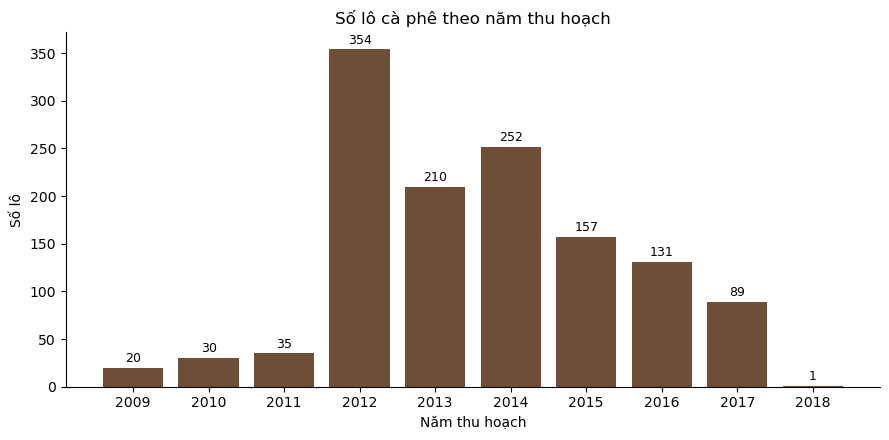

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(lots_per_year.index.astype(str), lots_per_year.values, color="#6F4E37")

ax.bar_label(bars, padding=2, fontsize=9)          # ghi số lô lên đầu mỗi cột
ax.set_title("Số lô cà phê theo năm thu hoạch")
ax.set_xlabel("Năm thu hoạch")
ax.set_ylabel("Số lô")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Nhận xét — giai đoạn:**
- Năm thu hoạch trải từ **2009 đến 2018**; có **60 lô (4,5%) thiếu năm thu hoạch**.
- Phần lớn lô tập trung trong giai đoạn **2012–2016** (chiếm khoảng 86,3% số lô có năm, tức 1.104/1.279 lô), nhiều nhất là năm **2012** với 354 lô.
- Các năm đầu (**2009–2011**: 20, 30, 35 lô) và năm cuối (**2018**) có rất ít lô (năm ít nhất chỉ 1 lô).
- Cột `Expiration` trải từ **09/04/2011 đến 19/01/2019**. Vì chứng nhận CQI có hạn 1 năm, các lô được chấm khoảng từ 04/2010 đến 01/2018; mốc cuối này khớp với thời điểm scrape tháng 01/2018 nêu ở phần (a).
- **Ảnh hưởng tới phân tích:** các năm quá ít lô không đủ để tính trung vị ổn định, nên câu Q4 (xu hướng theo năm) cần gộp hoặc loại các năm này và nêu rõ lý do; ngoài ra dữ liệu dừng ở 2018 nên không suy ra được xu hướng hiện tại.

#### (d) Độ phủ theo quốc gia: quốc gia nào chiếm nhiều lô, quốc gia nào quá ít?

In [22]:
# Độ phủ theo quốc gia
lots_per_country = df["Country.of.Origin"].value_counts()          # giảm dần sẵn

small = lots_per_country[lots_per_country < 10]
top3_share = lots_per_country.head(3).sum() / len(df)

print(f"Số quốc gia                 : {lots_per_country.size}")
print(f"Quốc gia có < 10 lô         : {small.size} nước, chiếm {small.sum()} lô ({small.sum() / len(df):.1%})")
print(f"Top 3 quốc gia chiếm        : {top3_share:.1%} tổng số lô")

lots_per_country.to_frame("Số lô").assign(**{"Tỷ lệ (%)": lambda t: (t["Số lô"] / len(df) * 100).round(2)})

Số quốc gia                 : 34
Quốc gia có < 10 lô         : 14 nước, chiếm 45 lô (3.4%)
Top 3 quốc gia chiếm        : 44.8% tổng số lô


,Số lô,Tỷ lệ (%)
Country.of.Origin,,
Mexico,236,17.63
Colombia,183,13.67
Guatemala,181,13.52
Brazil,132,9.86
United States,87,6.50
Taiwan,75,5.60
Honduras,53,3.96
Costa Rica,51,3.81
Ethiopia,44,3.29


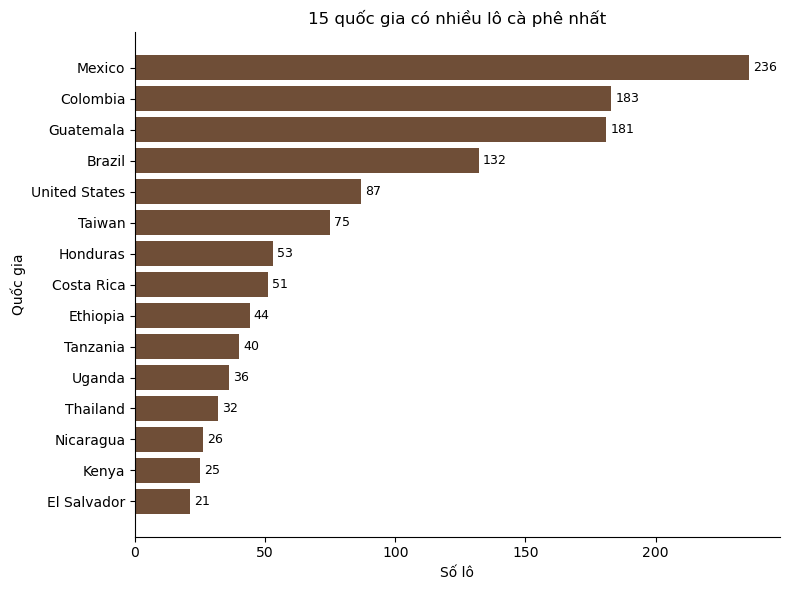

In [23]:
top15 = lots_per_country.head(15).sort_values()      # sắp tăng để cột dài nhất nằm trên cùng

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(top15.index, top15.values, color="#6F4E37")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("15 quốc gia có nhiều lô cà phê nhất")
ax.set_xlabel("Số lô")
ax.set_ylabel("Quốc gia")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#### (e) Hai file By_Country / By_Continent có phải nguồn dữ liệu độc lập không?

Giả thuyết: 2 file này là **bảng tổng hợp** tính từ file chính (`Rec_Cnt` = số lô, các cột `AVG_*` = trung bình). Kiểm tra bằng cách tự groupby file chính rồi so sánh.

In [24]:
for name, table in [("df_country", df_country), ("df_continent", df_continent)]:
    print(f"=== {name}: {table.shape} ===")
    print(list(table.columns))
    display(table.head())

=== df_country: (34, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Brazil,7.553106,7.573561,7.440530,7.511439,7.544545,7.531515,9.884924,9.853485,9.949394,0.082348,0.446970,0.128788,3.598485,132
1,Burundi,7.415000,7.460000,7.250000,7.415000,7.290000,7.415000,10.000000,10.000000,10.000000,0.060000,0.000000,0.000000,2.500000,2
2,China,7.641250,7.625625,7.484375,7.578125,7.573750,7.548125,9.958125,9.958125,9.916250,0.094375,0.500000,0.000000,4.000000,16
3,Colombia,7.653060,7.597104,7.524699,7.560000,7.609508,7.708415,9.934426,9.945355,9.952678,0.062022,0.207650,0.377049,1.939891,183
4,Costa Rica,7.671373,7.537255,7.534510,7.573922,7.537451,7.637255,9.856275,9.869216,9.908431,0.083333,0.117647,0.352941,2.823529,51


=== df_continent: (5, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Africa,7.759444,7.709444,7.623889,7.739074,7.680741,7.689938,9.954568,9.979321,9.813148,0.100926,0.166667,0.179012,3.734568,162
1,Asia,7.539121,7.499286,7.409231,7.478407,7.509066,7.473187,9.908187,9.970604,9.761813,0.079066,0.115385,0.752747,1.538462,182
2,North America,7.504346,7.445714,7.300767,7.496677,7.450977,7.432496,9.752632,9.734226,9.852992,0.096857,0.129323,0.566917,4.518797,665
3,Oceania,8.330000,8.420000,7.830000,8.330000,8.000000,8.250000,9.330000,9.330000,10.000000,0.120000,0.000000,0.000000,1.000000,1
4,South America,7.613415,7.589878,7.491585,7.545915,7.574756,7.629177,9.902866,9.894268,9.937470,0.070030,0.298780,0.301829,2.646341,328


In [25]:
# Groupby rồi so sánh
# 1. Dò tên cột trong df_country
key_col   = df_country.select_dtypes(exclude="number").columns[0]   # cột tên quốc gia
count_col = [c for c in df_country.columns if "cnt" in c.lower()][0] # cột Rec_Cnt
avg_cols  = [c for c in df_country.columns if c.upper().startswith("AVG")]

def match_raw_col(avg_col):
    """'AVG_Clean_Cup' -> 'Clean.Cup' (cột tương ứng trong df), không thấy thì trả None."""
    base = avg_col[4:].lower().replace("_", "").replace(".", "")
    for c in df.columns:
        if c.lower().replace(".", "").replace("_", "") == base:
            return c
    return None

avg_map = {a: match_raw_col(a) for a in avg_cols}
print("Cột khoá:", key_col, "| Cột đếm:", count_col)
print("Ánh xạ AVG -> cột gốc:", avg_map)

# 2. Tự tổng hợp từ file chính
raw_cols = [c for c in avg_map.values() if c is not None]
mine = (df.groupby("Country.of.Origin")
          .agg(n_lots=("REC_ID", "size"), **{f"mine_{c}": (c, "mean") for c in raw_cols})
          .reset_index())

# 3. Ghép với df_country để so sánh
compare = df_country.merge(mine, left_on=key_col, right_on="Country.of.Origin",
                           how="outer", indicator=True)
print(compare["_merge"].value_counts())
compare[[key_col, count_col, "n_lots"] + avg_cols[:2] + [f"mine_{c}" for c in raw_cols[:2]]].head(10)

Cột khoá: Country.of.Origin | Cột đếm: Rec_Cnt
Ánh xạ AVG -> cột gốc: {'AVG_Aroma': 'Aroma', 'AVG_Flavor': 'Flavor', 'AVG_Aftertaste': 'Aftertaste', 'AVG_Acidity': 'Acidity', 'AVG_Body': 'Body', 'AVG_Balance': 'Balance', 'AVG_Uniformity': 'Uniformity', 'AVG_Clean.Cup': 'Clean.Cup', 'AVG_Sweetness': 'Sweetness', 'AVG_Moisture': 'Moisture', 'AVG_Quakers': 'Quakers', 'AVG_Category.One.Defects': 'Category.One.Defects', 'AVG_Category.Two.Defects': 'Category.Two.Defects'}
_merge
both          34
left_only      0
right_only     0
Name: count, dtype: int64


,Country.of.Origin,Rec_Cnt,n_lots,AVG_Aroma,AVG_Flavor,mine_Aroma,mine_Flavor
0,Brazil,132,132,7.553106,7.573561,7.553106,7.573561
1,Burundi,2,2,7.415000,7.460000,7.415000,7.460000
2,China,16,16,7.641250,7.625625,7.641250,7.625625
3,Colombia,183,183,7.653060,7.597104,7.653060,7.597104
4,Costa Rica,51,51,7.671373,7.537255,7.671373,7.537255
5,Cote dIvoire,1,1,7.420000,7.250000,7.420000,7.250000
6,Ecuador,3,3,7.583333,7.640000,7.583333,7.640000
7,El Salvador,21,21,7.674762,7.654286,7.674762,7.654286
8,Ethiopia,44,44,7.896364,8.009091,7.896364,8.009091
9,Guatemala,181,181,7.544862,7.489006,7.544862,7.489006


In [26]:
# TEST
both = compare[compare["_merge"] == "both"]

# a) mọi quốc gia đều khớp tên
assert (compare["_merge"] == "both").all(), \
    f"Có quốc gia không khớp tên:\n{compare.loc[compare['_merge'] != 'both', [key_col, 'Country.of.Origin', '_merge']]}"

# b) số lô khớp Rec_Cnt
assert (both[count_col] == both["n_lots"]).all(), \
    f"Số lô lệch ở:\n{both.loc[both[count_col] != both['n_lots'], [key_col, count_col, 'n_lots']]}"

# c) trung bình khớp (làm tròn 2 chữ số vì file tổng hợp có thể đã làm tròn)
for avg_col, raw_col in avg_map.items():
    if raw_col is None:
        continue
    ok = np.allclose(both[avg_col], both[f"mine_{raw_col}"].round(2), atol=0.01)
    assert ok, f"{avg_col} không khớp với trung bình của {raw_col}"

print(f"df_country được tổng hợp từ df: khớp {len(both)} quốc gia, {len(avg_map)} cột AVG")

df_country được tổng hợp từ df: khớp 34 quốc gia, 13 cột AVG


**Kết luận — (e):**
- Cả 2 file `By_Country` (34 dòng) và `By_Continent` (5 dòng) đều là bảng tổng hợp tính ra từ file chính: `Rec_Cnt` khớp với số lô đếm được và 13 cột `AVG_*` khớp với trung bình tự tính cho cả 34 quốc gia và 5 châu lục. Sai lệch lớn nhất chỉ khoảng 10⁻¹⁵, là sai số dấu phẩy động, nên các giá trị trùng khớp hoàn toàn và file tổng hợp không hề làm tròn. Không có quốc gia hay châu lục nào lệch tên hoặc lệch số lô. *(Lưu ý: cột khoá của `By_Continent` bị đặt tên là `Country.of.Origin` dù chứa tên châu lục.)*
- Vì vậy 2 file này không chứa thông tin mới ngoài những gì một lệnh `groupby` trên file chính đã cho; chúng không phải nguồn dữ liệu độc lập.
- Về hình thức, nối với một bảng khác trong cùng bộ dữ liệu vẫn được tính là D1, nhưng phép nối như vậy không giúp trả lời được câu hỏi nào mới. Nhóm chọn nối với dữ liệu sản lượng FAOSTAT (câu Q5) vì nguồn này thực sự bổ sung thông tin bên ngoài (quy mô sản xuất của từng quốc gia) mà bộ CQI không có. File `By_Country` chỉ được giữ làm phương án dự phòng cho D1 và để đối chiếu.

#### (f) Hạn chế và thiên lệch đã biết

| Hạn chế | Bằng chứng từ dữ liệu | Ảnh hưởng tới phân tích |
|---|---|---|
| Thiên lệch chọn mẫu: chỉ có những lô được **gửi tới CQI để chấm**, không đại diện cho mọi lô cà phê trên thế giới | (lý luận, không có số) | Kết luận chỉ áp dụng cho các lô được gửi chấm |
| Mất cân bằng loài | Arabica 1.311 lô (97,91%) / Robusta 28 lô (2,09%) | Có thể chỉ phân tích Arabica |
| Độ phủ quốc gia không đều | 14/34 quốc gia có < 10 lô (tổng 45 lô, 3,4%), 6 nước chỉ có 1 lô; top 3 quốc gia (Mexico, Colombia, Guatemala) chiếm 44,8% | So sánh giữa các nước nhỏ không ổn định |
| Dữ liệu cũ, phân bố năm không đều | Năm thu hoạch 2009–2018, 60 lô (4,5%) thiếu năm; năm ít nhất (2018) chỉ có 1 lô, trong khi 2012 có 354 lô | Không suy ra xu hướng hiện tại |
| Thiếu một số biến quan trọng | Không có tổng điểm, điểm cupper, độ cao, giá | Nhóm phải tự tạo `total_9` |
| Dữ liệu scrape rồi chỉnh sửa, có thể có lỗi nhập liệu | Chi tiết ở 3.2 (giá trị 0, outlier) | Cần làm sạch trước khi phân tích |

**Collection method:**

- **Cách thu thập:** dữ liệu không do nhóm tự thu thập mà được scrape bằng script Python từ cơ sở dữ liệu công khai của CQI (01/2018). Bộ dữ liệu sau đó qua tay nhiều người trên Kaggle (Volpatto 2019, Boyar 2023) trước khi RealDealAdamP chỉnh sửa và công bố bản nhóm dùng (03/2024).
- **Quần thể:** 1.339 lô cà phê đã được Q Grader của CQI chấm điểm, đến từ 34 quốc gia thuộc 5 châu lục. Gần như toàn bộ là Arabica (97,91%); châu Mỹ chiếm hơn 74% số lô (Bắc Mỹ 49,66%, Nam Mỹ 24,50%).
- **Giai đoạn:** năm thu hoạch 2009–2018, tập trung ở 2012–2016 (86,3% số lô có năm); theo `Expiration`, các lô được chấm khoảng 04/2010–01/2018, khớp với thời điểm scrape. Hai file `By_Country`/`By_Continent` chỉ là bảng tổng hợp từ file chính nên không mở rộng thêm phạm vi dữ liệu.
- **Hạn chế:** mẫu chỉ gồm các lô được gửi tới CQI (thiên lệch chọn mẫu), mất cân bằng loài, độ phủ quốc gia rất lệch (14 nước có < 10 lô, top 3 nước chiếm 44,8%), dữ liệu đã cũ và thiếu tổng điểm, độ cao, giá. Vì vậy kết luận của nhóm chỉ áp dụng cho **các lô Arabica được chấm bởi CQI trong khoảng 2010–2018**, và các so sánh liên quan tới nước hoặc năm ít lô cần được gộp/loại và nêu rõ.

### 3.1.5. Motivation

Nhóm chọn bộ *Coffee Quality with Locations of Origin* vì 4 lý do:

**1. Chủ đề có ý nghĩa thực tế.** Điểm cupping của CQI được dùng làm thước đo chung khi mua bán cà phê nhân: lô đạt từ 80 điểm trở lên được xếp là cà phê đặc sản (specialty) và thường bán được giá cao hơn. Vì vậy câu hỏi *"điều gì gắn với một lô cà phê chất lượng cao?"* có người dùng cụ thể:
- **Nông hộ, hợp tác xã:** nên chọn giống, cách sơ chế nào, và cần kiểm soát độ ẩm, lỗi hạt ra sao trước khi gửi chấm.
- **Nhà nhập khẩu, nhà rang xay:** nên tìm nguồn hàng ở quốc gia, châu lục nào; quốc gia sản xuất nhiều có đồng nghĩa với chất lượng cao không.
- **Barista, người tiêu dùng:** điểm số ghi trên bao bì thực sự phản ánh những thuộc tính nào của tách cà phê.

**2. Dữ liệu phù hợp với yêu cầu đồ án.**
- *Dữ liệu thật:* 1.339 lô được Q Grader chấm, scrape từ cơ sở dữ liệu công khai của CQI (3.1.4a), không phải dữ liệu mô phỏng.
- *Đủ loại biến:* 13 biến số (9 thuộc tính cảm quan, độ ẩm, quakers, 2 loại lỗi hạt), các biến phân loại (loài, châu lục, 34 quốc gia, giống, màu hạt, cách sơ chế) và 2 biến thời gian (`Harvest.Year` 2009–2018, `Expiration`).
- *Đủ chất liệu cho các tiêu chí chiều sâu:* tự tạo biến `total_9` từ 9 thuộc tính cảm quan (D3); xu hướng theo năm (D2); kiểm tra một quan hệ có còn đúng trong từng quốc gia hoặc từng cách sơ chế không (D4); và có khoá quốc gia–năm để nối với dữ liệu sản lượng FAOSTAT (D1), nguồn bổ sung thông tin mà 2 file `By_Country`/`By_Continent` không có (3.1.4e).
- *Có bài toán ML tự nhiên:* dự đoán chất lượng của lô từ xuất xứ, cách sơ chế và các đặc tính vật lý của hạt.
- *Kích thước vừa phải:* 1.339 × 22, đủ để thống kê có ý nghĩa ở các nhóm lớn mà vẫn chạy nhanh. Các hạn chế (mất cân bằng loài, quốc gia ít lô, dữ liệu dừng ở 2018) đã được nhóm đo và ghi lại ở 3.1.4f để xử lý chủ động.

**3. Chưa bị khai thác quá nhiều.** Khác với Iris hay Titanic, bộ dữ liệu này ít được dùng làm ví dụ mẫu. TODO (Hiếu, theo `docs/related_work.md`): ghi số notebook công khai trên Kaggle và các notebook đó thường làm gì, để chỉ ra câu hỏi của nhóm khác họ ở đâu.

**4. Liên hệ với câu hỏi của nhóm.**
- **Q2 (ML):** 
- **Q4:** 
- **Q5:** 

### 3.1.6. Các file dữ liệu và cách nhóm sử dụng

In [47]:
# Tóm tắt 3 file
row_meaning = {
    MAIN_FILE.name:      "Một lô cà phê được CQI chấm điểm",
    COUNTRY_FILE.name:   "Một quốc gia (trung bình các chỉ số + số lô)",
    CONTINENT_FILE.name: "Một châu lục (trung bình các chỉ số + số lô)",
}
tables = {MAIN_FILE.name: df, COUNTRY_FILE.name: df_country, CONTINENT_FILE.name: df_continent}

files_summary = pd.DataFrame({
    "File":          list(tables.keys()),
    "Số dòng":       [t.shape[0] for t in tables.values()],
    "Số cột":        [t.shape[1] for t in tables.values()],
    "Một dòng là gì": [row_meaning[name] for name in tables],
})
files_summary

,File,Số dòng,Số cột,Một dòng là gì
0,Coffee_Qlty.csv,1339,22,Một lô cà phê được CQI chấm điểm
1,Coffee_Qlty_By_Country.csv,34,15,Một quốc gia (trung bình các chỉ số + số lô)
2,Coffee_Qlty_By_Continent.csv,5,15,Một châu lục (trung bình các chỉ số + số lô)


| File | Kích thước | Nội dung | Dùng cho |
|---|---|---|---|
| `Coffee_Qlty.csv` | 1.339 dòng × 22 cột | Mỗi dòng là một lô cà phê được CQI chấm điểm | File chính: exploration (3.2), Q1–Q6, mô hình ML |
| `Coffee_Qlty_By_Country.csv` | 34 dòng × 15 cột | Trung bình 13 chỉ số theo quốc gia (`AVG_*`) và số lô (`Rec_Cnt`) | Chỉ dùng để đối chiếu, phương án dự phòng cho D1 (đã kiểm chứng ở 3.1.4e) |
| `Coffee_Qlty_By_Continent.csv` | 5 dòng × 15 cột | Trung bình 13 chỉ số theo châu lục và số lô; cột khoá bị đặt tên `Country.of.Origin` dù chứa tên châu lục | Chỉ dùng để đối chiếu |


---
## 3.2. Data exploration


### 3.2.1. Overview
*(Đức Thịnh — `feat/eda-numeric`)*

### 3.2.2. Numerical columns
*(Đức Thịnh — `feat/eda-numeric`)*

### 3.2.3. Categorical columns
*(Tùng Hiếu — `feat/eda-categorical`)*

### 3.2.4. Missing data
*(Đức Thịnh — `feat/eda-numeric`)*

### 3.2.5. Relationships
*(Tùng Hiếu — `feat/eda-categorical`)*

### 3.2.6. Summary
*(Tùng Hiếu — `feat/eda-categorical`)*

---
✅ **Trước khi commit:** *Kernel → Restart & Run All*. Mọi ô `# TEST` phải chạy qua, mọi ô ✍️ phải có câu trả lời.

---
# Tài liệu tham khảo

[1] RealDealAdamP. *Coffee Quality with Locations of Origin*. Kaggle. https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin

[2] Coffee Quality Institute. https://www.coffeeinstitute.org

[3] Creative Commons. *Attribution-ShareAlike 4.0 International (CC BY-SA 4.0)*. https://creativecommons.org/licenses/by-sa/4.0/

[4] J. LeDoux. *coffee-quality-database*. GitHub. https://github.com/jldbc/coffee-quality-database

[5] J. VanderPlas. *Python Data Science Handbook*. O'Reilly, 2016.

[6] D. Volpatto. *Coffee Quality database from CQI*. Kaggle. https://www.kaggle.com/datasets/volpatto/coffee-quality-database-from-cqi

[7] F. Boyar. *Coffee Quality Data (CQI May-2023)*. Kaggle. https://www.kaggle.com/datasets/fatihb/coffee-quality-data-cqi

[8] Specialty Coffee Association. *Protocols & Best Practices*. https://sca.coffee/research/protocols-best-practices